### Análise Exploratória (EDA)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuracao visual dos graficos

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

In [ ]:
# Carregando o dataset tratado na Etapa 1

df = pd.read_csv('seoul_bike_tratado.csv')
df['date'] = pd.to_datetime(df['date'])
df['timestamp'] = pd.to_datetime(df['timestamp'])

df.head()

,date,rented_bike_count,hour,temperature(°c),humidity(%),wind_speed_(m/s),visibility_(10m),dew_point_temperature(°c),solar_radiation_(mj/m2),rainfall(mm),snowfall_(cm),seasons,holiday,functioning_day,timestamp
0,2017-12-01,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,2017-12-01 00:00:00
1,2017-12-01,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,2017-12-01 01:00:00
2,2017-12-01,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes,2017-12-01 02:00:00
3,2017-12-01,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,2017-12-01 03:00:00
4,2017-12-01,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes,2017-12-01 04:00:00


In [11]:
# Para a analise exploratoria de demanda, o foco é nos dias em que o sistema funcionou

df_func = df[df['functioning_day'] == 'Yes']

print(f"Total de registros operacionais: {len(df_func)}")
df_func.head()

Total de registros operacionais: 8465


,date,rented_bike_count,hour,temperature(°c),humidity(%),wind_speed_(m/s),visibility_(10m),dew_point_temperature(°c),solar_radiation_(mj/m2),rainfall(mm),snowfall_(cm),seasons,holiday,functioning_day,timestamp
0,2017-12-01,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,2017-12-01 00:00:00
1,2017-12-01,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,2017-12-01 01:00:00
2,2017-12-01,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes,2017-12-01 02:00:00
3,2017-12-01,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,2017-12-01 03:00:00
4,2017-12-01,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes,2017-12-01 04:00:00


/tmp/ipykernel_29671/1063233115.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_func, x='seasons', y='rented_bike_count', palette='Set2', ax=axes[1])


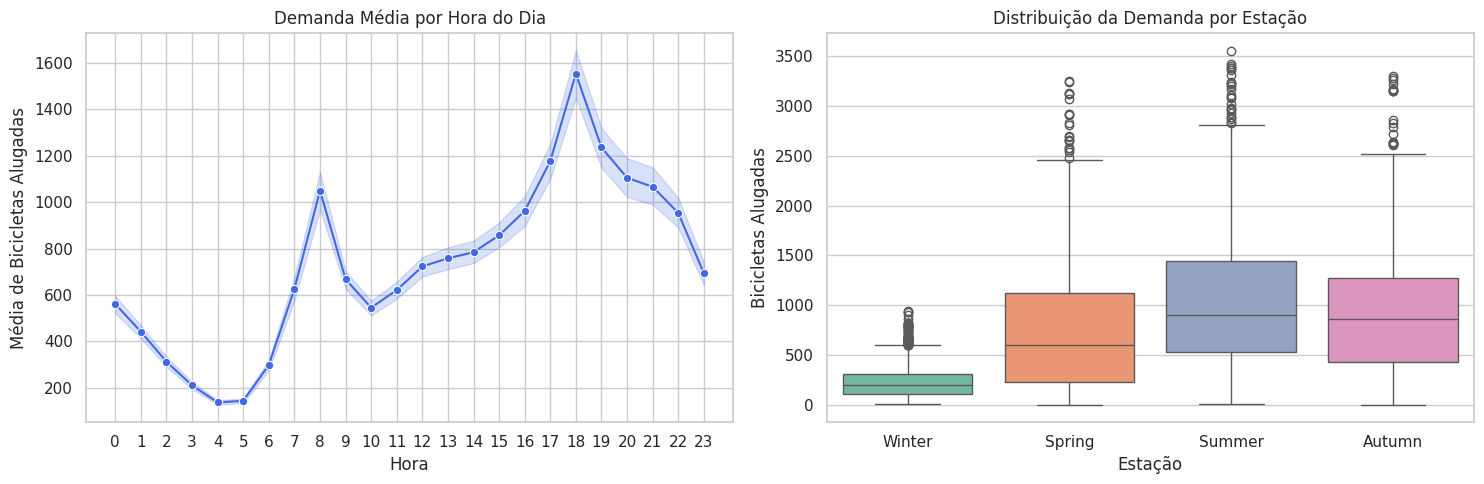

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Demanda media por hora do dia
sns.lineplot(data=df_func, x='hour', y='rented_bike_count', marker='o', color='royalblue', ax=axes[0])
axes[0].set_title('Demanda Média por Hora do Dia')
axes[0].set_xlabel('Hora')
axes[0].set_ylabel('Média de Bicicletas Alugadas')
axes[0].set_xticks(range(0, 24))

# Distribuicao da demanda por estação
sns.boxplot(data=df_func, x='seasons', y='rented_bike_count', palette='Set2', ax=axes[1])
axes[1].set_title('Distribuição da Demanda por Estação')
axes[1].set_xlabel('Estação')
axes[1].set_ylabel('Bicicletas Alugadas')

plt.tight_layout()
plt.show()

In [15]:
# Medidas numericas por estacao para confirmar a variabilidade
df_func.groupby('seasons')['rented_bike_count'].agg(['mean', 'median', 'std', 'min', 'max'])

,mean,median,std,min,max
seasons,,,,,
Autumn,924.110480,856.0,617.547879,2,3298
Spring,746.254167,599.0,618.667962,2,3251
Summer,1034.073370,905.5,690.244759,9,3556
Winter,225.541204,203.0,150.372236,3,937


O primeiro gráfico responde a pergunta:  Quais horários têm maior demanda? <p>

O gráfico tem 2 picos um na parte da manhã às 8h (média de quase 1.000 bikes) e outro pico na parte da tarde entre 17h e 19h (com top às 18h). Isso pode significar que as bikes são utilizadas para transporte de trabalho/estudo e não só para lazer

O segundo gráfico e tabela respondem a pergunta: Qual estação do ano tem maior média e qual tem maior variabilidade? <p>

Pela tabela conseguimos ver que no Verão apresenta uma maior média no aluguel das bicicletas, e pelo boxplot conseguimos ver que no verão também temos uma maior variabilidade tanto pelo tamanho da sua caixa quanto o tamanho da sua hastes, que representam maior espalhamento dos dados. Destaque também para o inverno que tem a menor média (225) e menor desvio padrão (150) devido ao frio intenso.

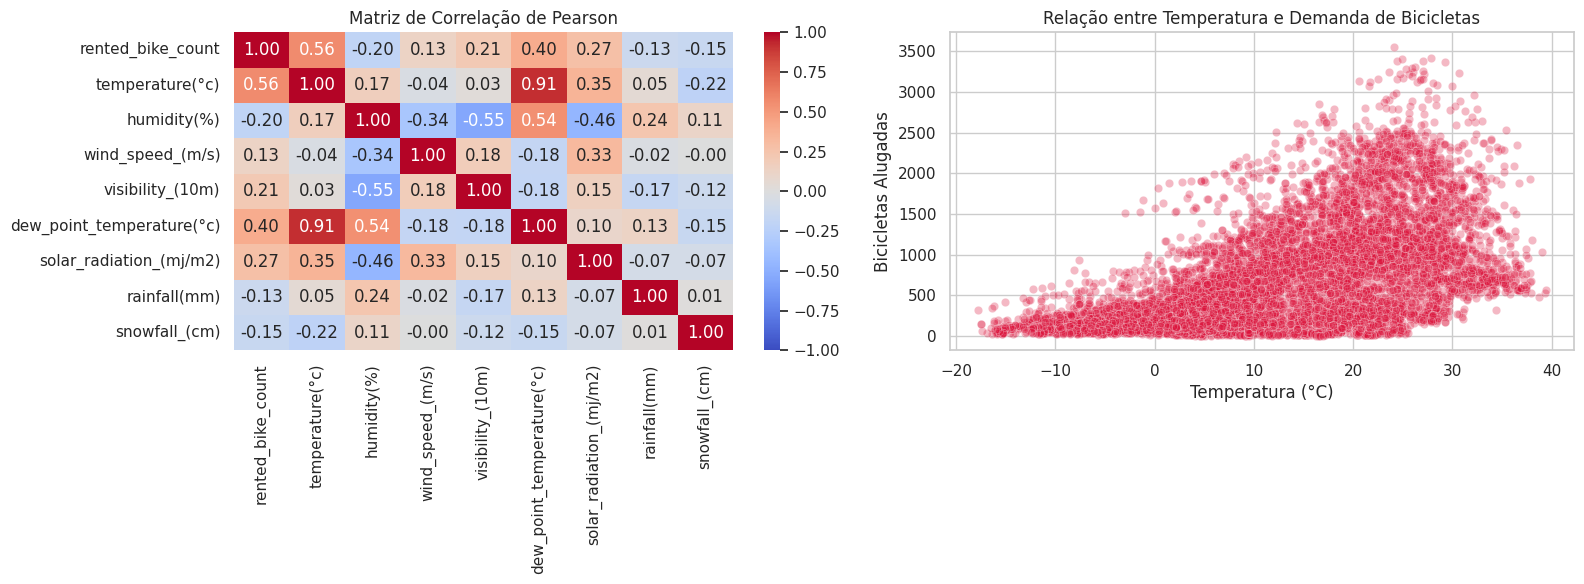

rented_bike_count            1.000000
temperature(°c)              0.562740
dew_point_temperature(°c)    0.400263
solar_radiation_(mj/m2)      0.273862
visibility_(10m)             0.212323
wind_speed_(m/s)             0.125022
rainfall(mm)                -0.128626
snowfall_(cm)               -0.151611
humidity(%)                 -0.201973
Name: rented_bike_count, dtype: float64

In [16]:
# Selecionando apenas variaveis numericas relevantes para correlacao
colunas_num = [
    'rented_bike_count', 'temperature(°c)', 'humidity(%)', 
    'wind_speed_(m/s)', 'visibility_(10m)', 'dew_point_temperature(°c)',
    'solar_radiation_(mj/m2)', 'rainfall(mm)', 'snowfall_(cm)'
]

corr = df_func[colunas_num].corr()

# Plotando o Mapa de Calor (Heatmap) e a Dispersao com Temperatura
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Heatmap de correlacao
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title('Matriz de Correlação de Pearson')

# Dispersao: Temperatura vs Aluguel de Bicicletas
sns.scatterplot(data=df_func, x='temperature(°c)', y='rented_bike_count', alpha=0.3, color='crimson', ax=axes[1])
axes[1].set_title('Relação entre Temperatura e Demanda de Bicicletas')
axes[1].set_xlabel('Temperatura (°C)')
axes[1].set_ylabel('Bicicletas Alugadas')

plt.tight_layout()
plt.show()

# Verificando as correlacoes diretas com a variavel alvo ordenada
corr['rented_bike_count'].sort_values(ascending=False)